# 02 — Análisis exploratorio de variables predictoras

Este notebook parte del archivo `DataSet_depurado_basico_EDA.xlsx` generado por el notebook 01.

Su propósito es:

- Clasificar preliminarmente las variables;
- Excluir del análisis la variable objetivo y las variable identificador de alumno;
- Analizar cada variable predictora respecto de la variable nota;
- Obtener un ranking descriptivo de las diferencias entre clases.

El ranking es exploratorio: no representa causalidad ni importancia definitiva del modelo.

## 1. Importación de librerías

In [ ]:
import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga del dataset depurado

In [ ]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("No se seleccionó ningún archivo.")

ruta_archivo = next(iter(uploaded))
df_depurado = pd.read_excel(ruta_archivo)

print(f"Archivo cargado: {ruta_archivo}")
print(f"Filas: {df_depurado.shape[0]}")
print(f"Columnas: {df_depurado.shape[1]}")

display(df_depurado.head())

Saving DataSet_depurado_basico_EDA.xlsx to DataSet_depurado_basico_EDA.xlsx
Archivo cargado: DataSet_depurado_basico_EDA.xlsx
Filas: 978
Columnas: 125


,alumno,nota,tecnologia_pc_casa,tecnologia_pc_trabajo,tecnologia_pc_universidad,tecnologia_pc_otro_lugar,tecnologia_int_casa,tecnologia_int_trabajo,tecnologia_int_universidad,tecnologia_int_otro_lugar,deportes,deportes_universidad,deportes_gimnasio,deportes_particular,deportes_otro_lugar,deportes_basquet,deportes_futbol,deportes_gimnasia,deportes_handball,deportes_natacion,deportes_tenis,deportes_voley,deportes_otros,nivel_idioma_ingles,nivel_idioma_aleman,nivel_idioma_frances,nivel_idioma_italiano,nivel_idioma_portugues,nivel_idioma_chino,idioma_otro,nivel_idioma_otro,tecnologia_int_movil,condicion_discapacidad,tiene_cud,disc_auditiva,aud_tipo,aud_lenguaje_senias,aud_lenguaje_labial,aud_comunicacion_otra,aud_apoyo_vida_diaria,aud_req_interprete_lengua_senias,aud_req_aro_magnetico,aud_req_otros_apoyos,aud_otros_apoyos,disc_visual,vis_dificultad_para_ver,vis_apoyo_vida_diaria,vis_req_archivo_audio,vis_req_texto_digital,vis_req_texto_braile,vis_req_otros_apoyos,vis_otros_apoyos,disc_motora,mot_apoyo_vida_diaria,mot_req_apoyo_aula,mot_apoyo_aula,mot_req_otros_apoyos,mot_otros_apoyos,disc_cond_psicosocial,psi_descripcion,psi_apoyo_vida_diaria,psi_req_otros_apoyos,psi_otros_apoyos,disc_otra,otra_descripcion,otra_req_apoyo_vida_diaria,otra_apoyo_vida_diaria,informacion_importante,costeo_estudios_familiar,costeo_estudios_plan_social,costeo_estudios_trabajo,costeo_estudios_beca,costeo_estudios_otro,costeo_estudios_descripcion,beca,beca_fuente_universidad,beca_fuente_nacional,beca_fuente_provincial,beca_fuente_municipal,beca_fuente_internacional,beca_fuente_otra,beca_tipo_economica,beca_tipo_servicios,beca_tipo_investigacion,beca_economica_transporte,beca_economica_efectivo,beca_economica_fotocopias,beca_economica_habitacional,beca_economica_comedor,trabajo_existe,trabajo_hace,trabajo_familiar,trabajo_con_descuentos_jubilatorios,trabajo_recibe_pago,trabajo_ocupacion,trabajo_hora_sem,trabajo_carrera,trabajo_tarea_descripcion,estado_civil,unido_hecho,situacion_padre,situacion_madre,cantidad_hijos,cantidad_familia,turno_preferido,cobertura_salud,tipo_vivienda,vive_con,procedencia_calle,procedencia_numero,procedencia_piso,procedencia_departamento,procedencia_unidad,procedencia_localidad,procedencia_barrio,procedencia_codigo_postal,es_celiaco,mot_vocacion,mot_sugerencia_familiar,mot_reconocimiento_social,mot_insercion_laboral,mot_perfil_profesional,mot_mejora_economica,mot_util_sociedad,mot_otros_p
0,25342,A,S,S,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,NaN,NaN,NaN,N,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,S,N,N,1.0,4.0,1.0,NaN,2,N,V,V,0,0,3.0,2,5.0,3.0,Jose Hernandez 525,525,0,0,0,5436,Hipotecario,3530.0,N,N,S,N,N,N,N,N,N
1,25567,R,S,N,S,N,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,N,N,N,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,3.0,S,N,S,2.0,2.0,3.0,NaN,1,N,N,V,0,0,NaN,1,NaN,NaN,17 Entre 0 Y 00 Superiora Palmira,172,NaN,NaN,NaN,6036,NaN,3700.0,N,N,N,N,N,N,N,N,N
2,28277,U,S,N,N,N,S,N,N,N,S,N,N,S,N,N,N,N,N,N,N,N,S,3.0,4.0,3.0,4.0,3.0,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,NaN,Compra Y Venta,1,N,V,V,0,3,1.0,5,5.0,3.0,San JosÃ©,10,NaN,NaN,NaN,5342,San JosÃ©,3514.0,N,N,N,N,S,N,N,N,N
3,27014,A,S,N,S,N,S,N,S,N,S,N,N,S,N,S,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,4.0,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,2.0,TÃ©cnico InformÃ¡tico,1,N,V,V,0,0,1.0,5,6.0,3.0,Mza 4 Pc 11,NaN,NaN,NaN,NaN,6167,Victor Arrudi,3730.0,N,N,S,S,S,S,S,S,N
4,32446,R,S,N,N,N,S,N,N,S,S,N,N,S,N,N,N,N,N,N,N,S,N,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN

## 3. Configuración del análisis

In [ ]:
variable_objetivo = "nota"

# Modificar esta lista si el dataset contiene otros identificadores.
variables_identificatorias = [
    "alumno"
]

if variable_objetivo not in df_depurado.columns:
    raise ValueError(
        f"No se encontró la variable objetivo '{variable_objetivo}'."
    )

variables_identificatorias = [
    col for col in variables_identificatorias
    if col in df_depurado.columns
]

print("Variable objetivo:", variable_objetivo)
print("Identificadores encontrados:", variables_identificatorias)

Variable objetivo: nota
Identificadores encontrados: ['alumno']


## 4. Preparación mínima para el análisis

In [ ]:
df_eda = df_depurado.copy()

columnas_100_faltantes = df_eda.columns[
    df_eda.isna().all()
].tolist()

df_eda = df_eda.drop(columns=columnas_100_faltantes)

print("Columnas con 100% de faltantes eliminadas:")
print(columnas_100_faltantes)

print("\nDimensiones del dataset para análisis:")
print(df_eda.shape)

Columnas con 100% de faltantes eliminadas:
['aud_comunicacion_otra', 'aud_apoyo_vida_diaria', 'aud_otros_apoyos', 'vis_otros_apoyos', 'mot_apoyo_aula', 'mot_otros_apoyos', 'psi_descripcion', 'psi_apoyo_vida_diaria', 'psi_otros_apoyos', 'otra_apoyo_vida_diaria']

Dimensiones del dataset para análisis:
(978, 115)


## 5. Clasificación preliminar de variables

In [ ]:
def clasificar_variable(serie):
    serie_no_nula = serie.dropna()
    n_unicos = serie_no_nula.nunique()

    if n_unicos <= 1:
        return "sin_variabilidad"

    valores = set(
        serie_no_nula
        .astype(str)
        .str.strip()
        .str.upper()
        .unique()
    )

    if n_unicos == 2 and valores.issubset(
        {"S", "N", "0", "1", "0.0", "1.0", "SI", "NO", "SÍ"}
    ):
        return "binaria"

    if pd.api.types.is_numeric_dtype(serie):
        if n_unicos <= 10:
            return "ordinal_discreta"
        return "numerica_o_codigo"

    if n_unicos > 30:
        return "alta_cardinalidad_texto"

    return "categorica_nominal"


registros_resumen = []

for col in df_eda.columns:
    if col == variable_objetivo:
        tipo = "objetivo"
    elif col in variables_identificatorias:
        tipo = "identificador"
    else:
        tipo = clasificar_variable(df_eda[col])

    registros_resumen.append({
        "variable": col,
        "tipo_variable": tipo,
        "tipo_dato_pandas": str(df_eda[col].dtype),
        "valores_unicos": df_eda[col].nunique(dropna=True),
        "faltantes": int(df_eda[col].isna().sum()),
        "porcentaje_faltantes": round(
            df_eda[col].isna().mean() * 100, 2
        )
    })

resumen_variables = pd.DataFrame(registros_resumen)

display(resumen_variables)

resumen_tipos = (
    resumen_variables["tipo_variable"]
    .value_counts()
    .rename_axis("tipo_variable")
    .reset_index(name="cantidad")
)

print("\nResumen por tipo de variable:")
display(resumen_tipos)

,variable,tipo_variable,tipo_dato_pandas,valores_unicos,faltantes,porcentaje_faltantes
0,alumno,identificador,int64,343,0,0.00
1,nota,objetivo,object,3,0,0.00
2,tecnologia_pc_casa,binaria,object,2,0,0.00
3,tecnologia_pc_trabajo,binaria,object,2,0,0.00
4,tecnologia_pc_universidad,binaria,object,2,0,0.00
5,tecnologia_pc_otro_lugar,binaria,object,2,0,0.00
6,tecnologia_int_casa,binaria,object,2,8,0.82
7,tecnologia_int_trabajo,binaria,object,2,8,0.82
8,tecnologia_int_universidad,binaria,object,2,8,0.82
9,tecnologia_int_otro_lugar,binaria,object,2,8,0.82



Resumen por tipo de variable:


,tipo_variable,cantidad
0,binaria,54
1,sin_variabilidad,24
2,ordinal_discreta,19
3,categorica_nominal,8
4,alta_cardinalidad_texto,6
5,numerica_o_codigo,2
6,identificador,1
7,objetivo,1


## 6. Variables sin variabilidad y candidatas para análisis

In [ ]:
variables_sin_variabilidad = resumen_variables.loc[
    resumen_variables["tipo_variable"] == "sin_variabilidad",
    "variable"
].tolist()

tipos_validos_para_eda = [
    "binaria",
    "categorica_nominal",
    "ordinal_discreta",
    "numerica_o_codigo"
]

variables_eda = resumen_variables.loc[
    resumen_variables["tipo_variable"].isin(tipos_validos_para_eda),
    "variable"
].tolist()

variables_eda = [
    col for col in variables_eda
    if col not in variables_identificatorias
    and col != variable_objetivo
]

print("Variables sin variabilidad:", len(variables_sin_variabilidad))
print(variables_sin_variabilidad)

print("\nVariables candidatas para análisis:", len(variables_eda))
display(
    resumen_variables[
        resumen_variables["variable"].isin(variables_eda)
    ]
)

Variables sin variabilidad: 24
['tiene_cud', 'disc_auditiva', 'aud_tipo', 'aud_lenguaje_senias', 'aud_lenguaje_labial', 'aud_req_interprete_lengua_senias', 'aud_req_aro_magnetico', 'aud_req_otros_apoyos', 'vis_req_archivo_audio', 'vis_req_texto_braile', 'vis_req_otros_apoyos', 'disc_motora', 'mot_apoyo_vida_diaria', 'mot_req_apoyo_aula', 'mot_req_otros_apoyos', 'disc_cond_psicosocial', 'psi_req_otros_apoyos', 'otra_req_apoyo_vida_diaria', 'beca_fuente_provincial', 'beca_fuente_municipal', 'beca_fuente_internacional', 'beca_fuente_otra', 'beca_tipo_investigacion', 'trabajo_con_descuentos_jubilatorios']

Variables candidatas para análisis: 83


,variable,tipo_variable,tipo_dato_pandas,valores_unicos,faltantes,porcentaje_faltantes
2,tecnologia_pc_casa,binaria,object,2,0,0.00
3,tecnologia_pc_trabajo,binaria,object,2,0,0.00
4,tecnologia_pc_universidad,binaria,object,2,0,0.00
5,tecnologia_pc_otro_lugar,binaria,object,2,0,0.00
6,tecnologia_int_casa,binaria,object,2,8,0.82
7,tecnologia_int_trabajo,binaria,object,2,8,0.82
8,tecnologia_int_universidad,binaria,object,2,8,0.82
9,tecnologia_int_otro_lugar,binaria,object,2,8,0.82
10,deportes,binaria,object,2,0,0.00
11,deportes_universidad,binaria,object,2,0,0.00


## 7. Grupos temáticos

Las listas se filtran automáticamente: si una variable no existe en el archivo, se informa pero no se produce un error.

In [ ]:
grupos_variables = {
    "Tecnológicas": [
        "tecnologia_pc_casa",
        "tecnologia_pc_trabajo",
        "tecnologia_pc_universidad",
        "tecnologia_int_casa",
        "tecnologia_int_universidad",
        "tecnologia_int_movil"
    ],
    "Hábitos y actividades": [
        "deportes",
        "deportes_universidad",
        "deportes_gimnasio",
        "deportes_particular",
        "deportes_futbol",
        "deportes_otros"
    ],
    "Idiomas": [
        "nivel_idioma_ingles",
        "nivel_idioma_portugues",
        "nivel_idioma_frances",
        "nivel_idioma_aleman"
    ],
    "Socioeconómicas": [
        "costeo_estudios_familiar",
        "costeo_estudios_trabajo",
        "costeo_estudios_beca",
        "beca",
        "beca_tipo_economica",
        "beca_economica_transporte",
        "beca_economica_comedor"
    ],
    "Laborales": [
        "trabajo_existe",
        "trabajo_hace",
        "trabajo_ocupacion",
        "trabajo_hora_sem",
        "trabajo_carrera",
        "trabajo_recibe_pago"
    ],
    "Familiares y personales": [
        "estado_civil",
        "situacion_padre",
        "situacion_madre",
        "cantidad_hijos",
        "cantidad_familia",
        "vive_con",
        "cobertura_salud",
        "tipo_vivienda"
    ],
    "Territoriales": [
        "procedencia_localidad",
        "procedencia_codigo_postal",
        "procedencia_barrio"
    ],
    "Motivacionales": [
        "mot_vocacion",
        "mot_sugerencia_familiar",
        "mot_reconocimiento_social",
        "mot_insercion_laboral",
        "mot_perfil_profesional",
        "mot_mejora_economica",
        "mot_util_sociedad",
        "mot_otros_p"
    ]
}

for grupo, variables in grupos_variables.items():
    existentes = [v for v in variables if v in df_eda.columns]
    no_encontradas = [v for v in variables if v not in df_eda.columns]

    print(f"\nGrupo: {grupo}")
    print(f"Variables encontradas: {len(existentes)}")

    if no_encontradas:
        print("Variables no encontradas:", no_encontradas)


Grupo: Tecnológicas
Variables encontradas: 6

Grupo: Hábitos y actividades
Variables encontradas: 6

Grupo: Idiomas
Variables encontradas: 4

Grupo: Socioeconómicas
Variables encontradas: 7

Grupo: Laborales
Variables encontradas: 6

Grupo: Familiares y personales
Variables encontradas: 8

Grupo: Territoriales
Variables encontradas: 3

Grupo: Motivacionales
Variables encontradas: 8


## 8. Funciones para tablas y gráficos

In [ ]:
def tabla_variable_vs_objetivo(
    df,
    variable,
    objetivo=variable_objetivo
):
    tabla_abs = pd.crosstab(
        df[variable],
        df[objetivo],
        dropna=False
    )

    tabla_pct = (
        pd.crosstab(
            df[variable],
            df[objetivo],
            normalize="index",
            dropna=False
        ) * 100
    ).round(2)

    return tabla_abs, tabla_pct


def graficar_variable_vs_objetivo(
    df,
    variable,
    objetivo=variable_objetivo,
    carpeta_salida=None
):
    tabla_pct = (
        pd.crosstab(
            df[variable],
            df[objetivo],
            normalize="index",
            dropna=False
        ) * 100
    ).round(2)

    if tabla_pct.empty:
        print(f"No se generó gráfico para {variable}: tabla vacía.")
        return

    ax = tabla_pct.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(
        f"Distribución porcentual de {objetivo} según {variable}"
    )
    ax.set_xlabel(variable)
    ax.set_ylabel("Porcentaje")
    ax.legend(title=objetivo)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if carpeta_salida is not None:
        carpeta = Path(carpeta_salida)
        carpeta.mkdir(parents=True, exist_ok=True)

        plt.savefig(
            carpeta / f"{variable}_vs_{objetivo}.png",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    plt.close()

## 9. Análisis automático por grupos


GRUPO: Tecnológicas

Variable: tecnologia_pc_casa
Frecuencias absolutas:


nota,A,R,U
tecnologia_pc_casa,,,
N,48,118,44
S,231,333,204


Porcentajes por categoría:


nota,A,R,U
tecnologia_pc_casa,,,
N,22.86,56.19,20.95
S,30.08,43.36,26.56


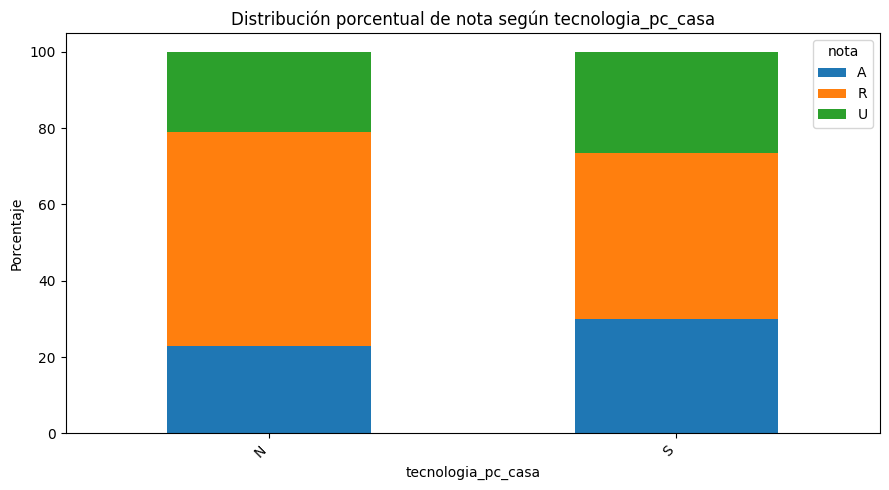


Variable: tecnologia_pc_trabajo
Frecuencias absolutas:


nota,A,R,U
tecnologia_pc_trabajo,,,
N,273,442,247
S,6,9,1


Porcentajes por categoría:


nota,A,R,U
tecnologia_pc_trabajo,,,
N,28.38,45.95,25.68
S,37.50,56.25,6.25


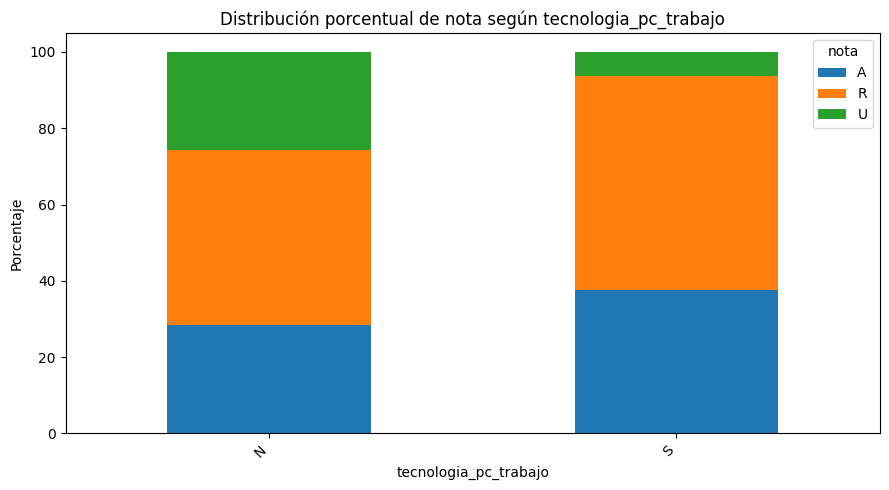


Variable: tecnologia_pc_universidad
Frecuencias absolutas:


nota,A,R,U
tecnologia_pc_universidad,,,
N,235,377,209
S,44,74,39


Porcentajes por categoría:


nota,A,R,U
tecnologia_pc_universidad,,,
N,28.62,45.92,25.46
S,28.03,47.13,24.84


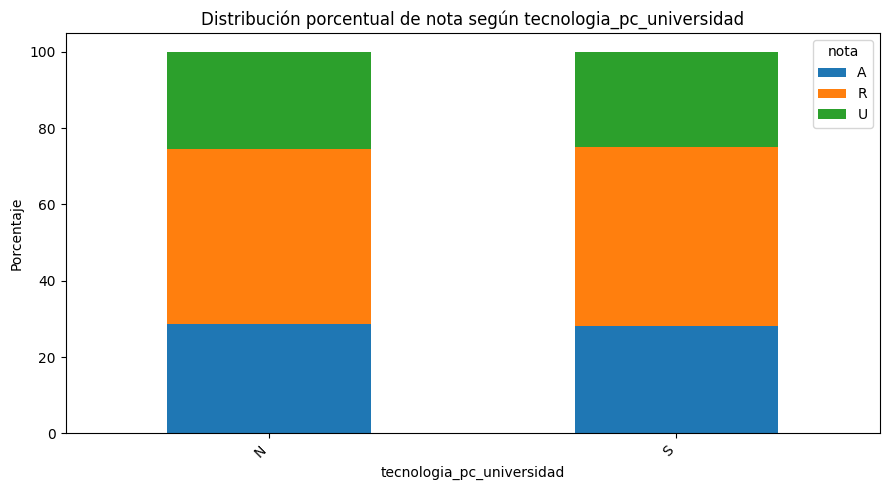


Variable: tecnologia_int_casa
Frecuencias absolutas:


nota,A,R,U
tecnologia_int_casa,,,
N,44,92,39
S,234,355,206
NaN,1,4,3


Porcentajes por categoría:


nota,A,R,U
tecnologia_int_casa,,,
N,25.14,52.57,22.29
S,29.43,44.65,25.91
NaN,12.50,50.00,37.50


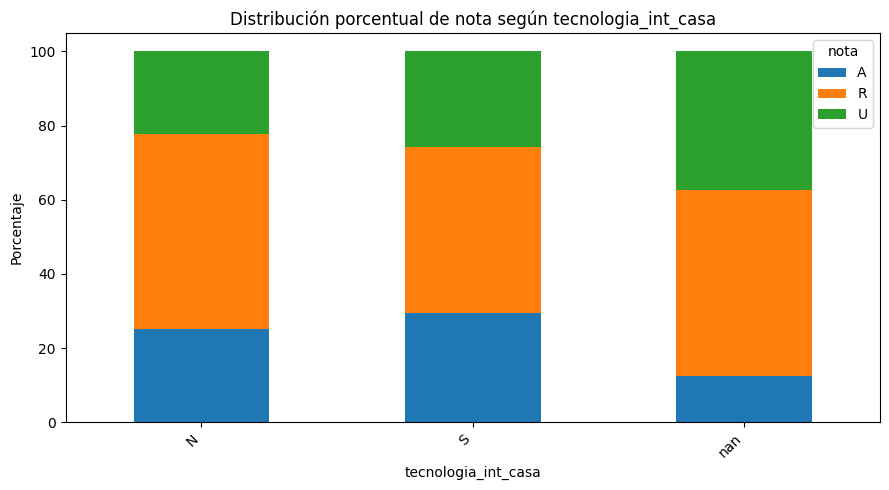


Variable: tecnologia_int_universidad
Frecuencias absolutas:


nota,A,R,U
tecnologia_int_universidad,,,
N,221,355,186
S,57,92,59
NaN,1,4,3


Porcentajes por categoría:


nota,A,R,U
tecnologia_int_universidad,,,
N,29.0,46.59,24.41
S,27.4,44.23,28.37
NaN,12.5,50.00,37.50


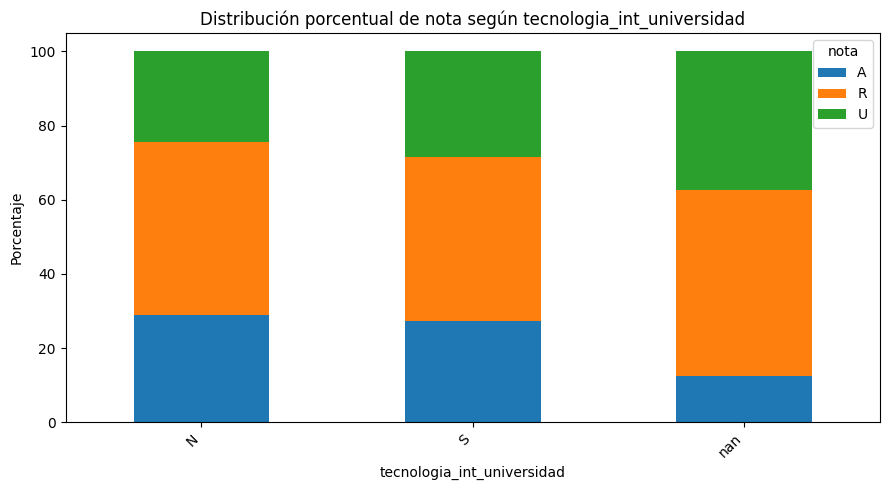


Variable: tecnologia_int_movil
Frecuencias absolutas:


nota,A,R,U
tecnologia_int_movil,,,
N,107,210,112
S,172,241,136


Porcentajes por categoría:


nota,A,R,U
tecnologia_int_movil,,,
N,24.94,48.95,26.11
S,31.33,43.90,24.77


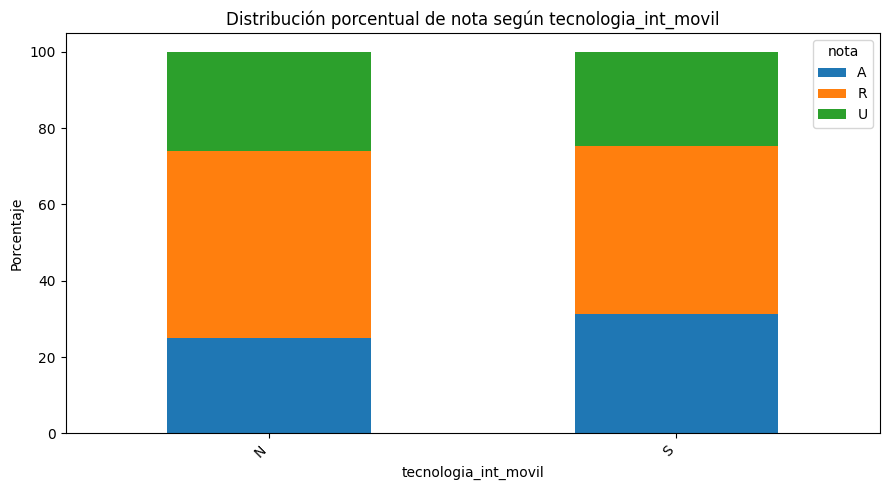


GRUPO: Hábitos y actividades

Variable: deportes
Frecuencias absolutas:


nota,A,R,U
deportes,,,
N,96,160,81
S,183,291,167


Porcentajes por categoría:


nota,A,R,U
deportes,,,
N,28.49,47.48,24.04
S,28.55,45.40,26.05


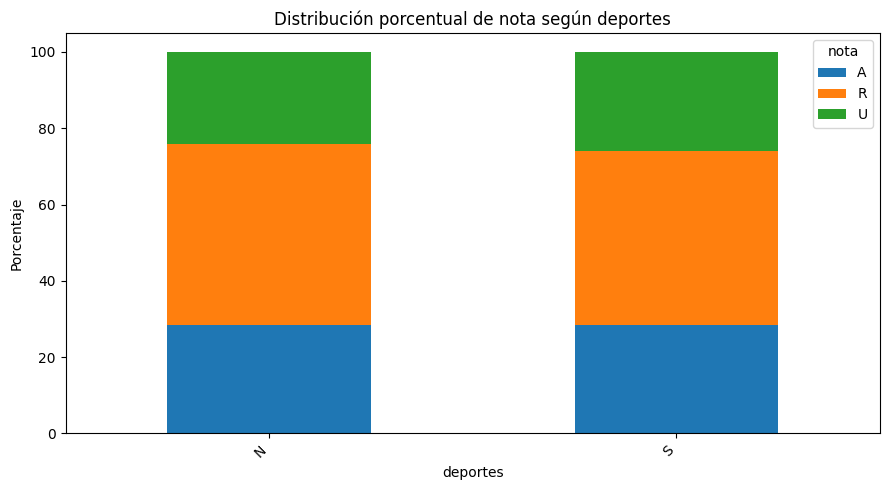


Variable: deportes_universidad
Frecuencias absolutas:


nota,A,R,U
deportes_universidad,,,
N,266,435,240
S,13,16,8


Porcentajes por categoría:


nota,A,R,U
deportes_universidad,,,
N,28.27,46.23,25.50
S,35.14,43.24,21.62


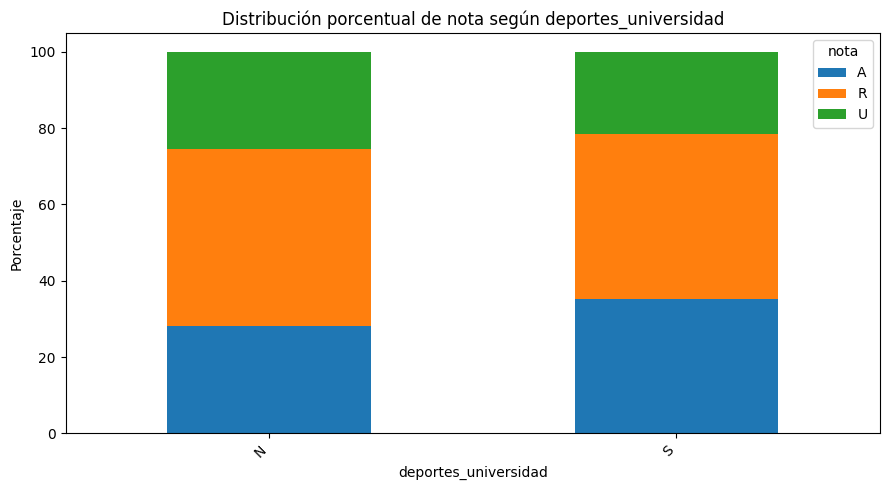


Variable: deportes_gimnasio
Frecuencias absolutas:


nota,A,R,U
deportes_gimnasio,,,
N,203,345,177
S,76,106,71


Porcentajes por categoría:


nota,A,R,U
deportes_gimnasio,,,
N,28.00,47.59,24.41
S,30.04,41.90,28.06


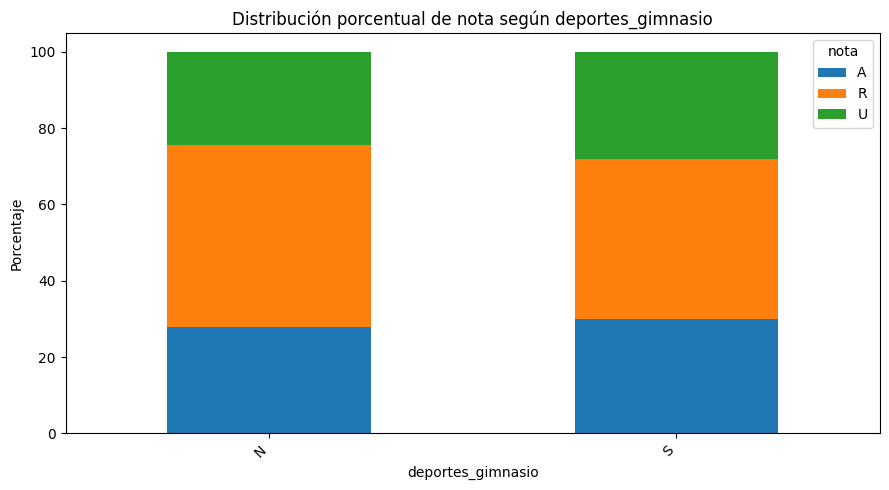


Variable: deportes_particular
Frecuencias absolutas:


nota,A,R,U
deportes_particular,,,
N,239,367,203
S,40,84,45


Porcentajes por categoría:


nota,A,R,U
deportes_particular,,,
N,29.54,45.36,25.09
S,23.67,49.70,26.63


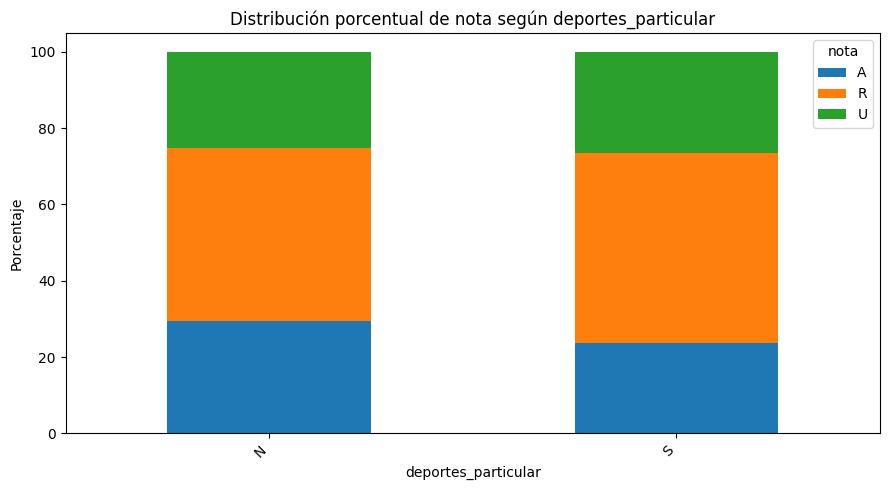


Variable: deportes_futbol
Frecuencias absolutas:


nota,A,R,U
deportes_futbol,,,
N,216,339,180
S,63,112,68


Porcentajes por categoría:


nota,A,R,U
deportes_futbol,,,
N,29.39,46.12,24.49
S,25.93,46.09,27.98


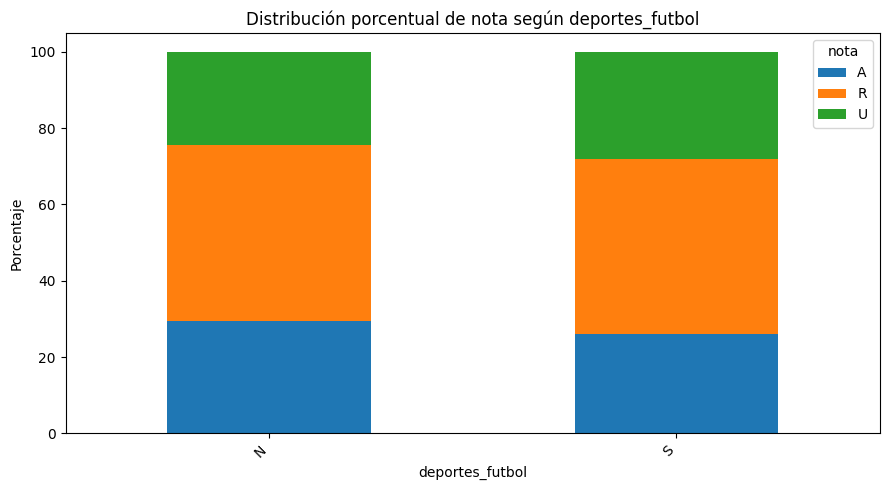


Variable: deportes_otros
Frecuencias absolutas:


nota,A,R,U
deportes_otros,,,
N,181,334,172
S,98,117,76


Porcentajes por categoría:


nota,A,R,U
deportes_otros,,,
N,26.35,48.62,25.04
S,33.68,40.21,26.12


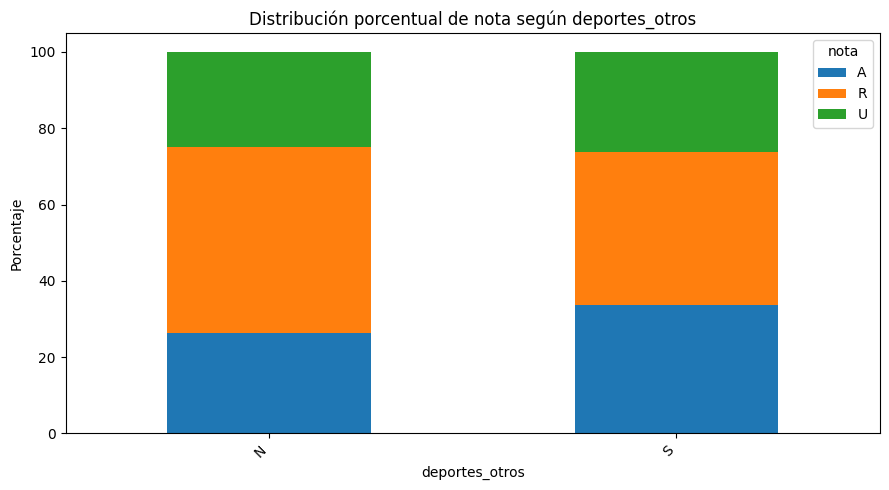


GRUPO: Idiomas

Variable: nivel_idioma_ingles
Frecuencias absolutas:


nota,A,R,U
nivel_idioma_ingles,,,
1.0,42,26,17
2.0,48,48,40
3.0,149,264,143
4.0,10,32,11
NaN,30,81,37


Porcentajes por categoría:


nota,A,R,U
nivel_idioma_ingles,,,
1.0,49.41,30.59,20.00
2.0,35.29,35.29,29.41
3.0,26.80,47.48,25.72
4.0,18.87,60.38,20.75
NaN,20.27,54.73,25.00


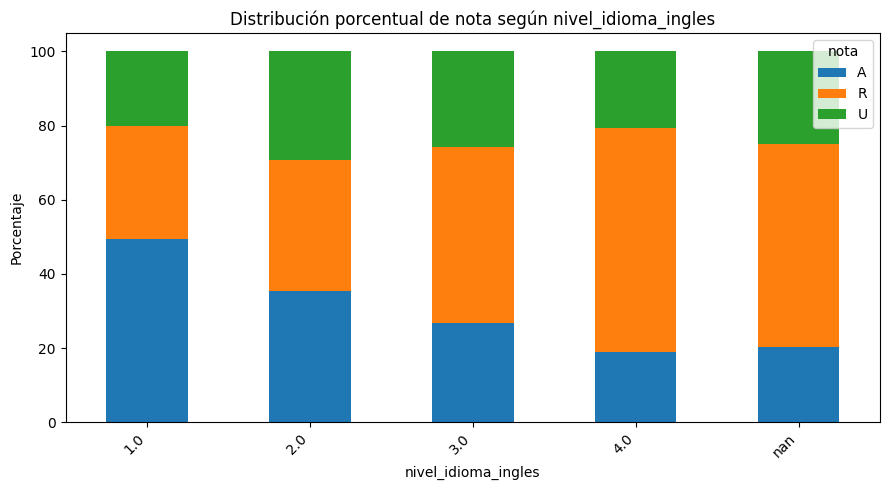


Variable: nivel_idioma_portugues
Frecuencias absolutas:


nota,A,R,U
nivel_idioma_portugues,,,
1.0,0,0,1
2.0,2,8,5
3.0,41,71,26
4.0,127,190,116
NaN,109,182,100


Porcentajes por categoría:


nota,A,R,U
nivel_idioma_portugues,,,
1.0,0.00,0.00,100.00
2.0,13.33,53.33,33.33
3.0,29.71,51.45,18.84
4.0,29.33,43.88,26.79
NaN,27.88,46.55,25.58


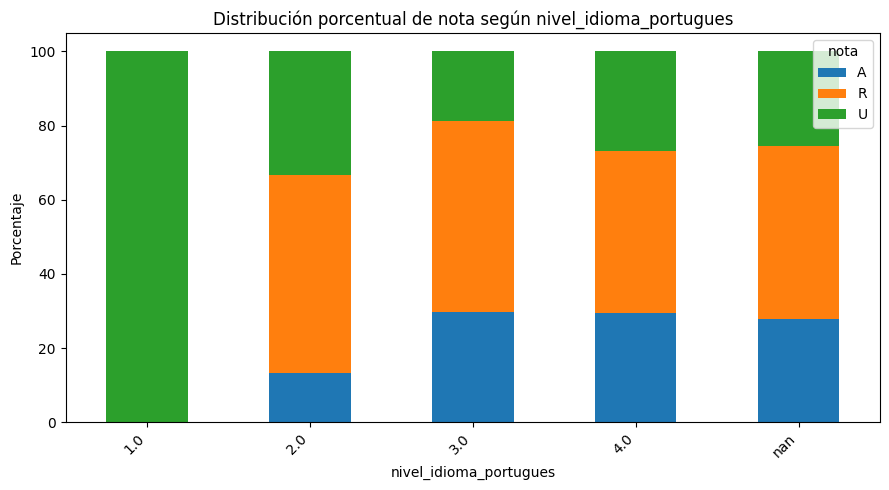


Variable: nivel_idioma_frances
Frecuencias absolutas:


nota,A,R,U
nivel_idioma_frances,,,
2.0,0,1,0
3.0,4,17,22
4.0,157,252,129
NaN,118,181,97


Porcentajes por categoría:


nota,A,R,U
nivel_idioma_frances,,,
2.0,0.00,100.00,0.00
3.0,9.30,39.53,51.16
4.0,29.18,46.84,23.98
NaN,29.80,45.71,24.49


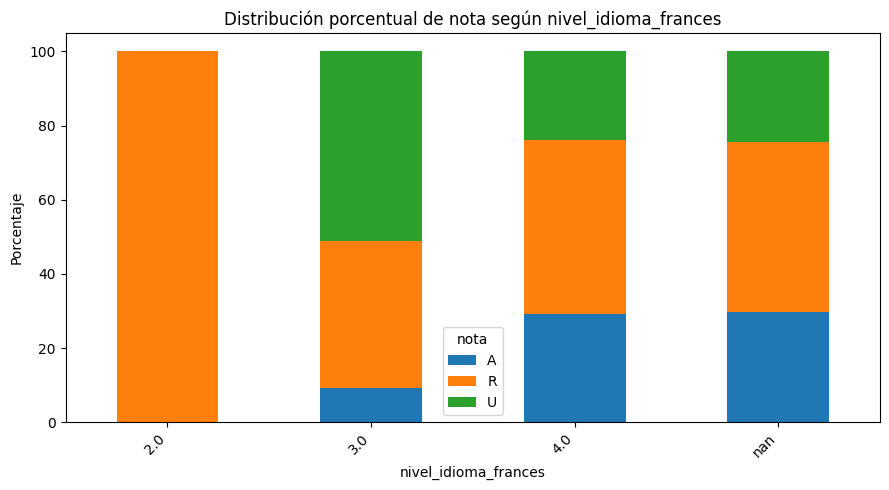


Variable: nivel_idioma_aleman
Frecuencias absolutas:


nota,A,R,U
nivel_idioma_aleman,,,
3.0,0,10,1
4.0,161,257,140
NaN,118,184,107


Porcentajes por categoría:


nota,A,R,U
nivel_idioma_aleman,,,
3.0,0.00,90.91,9.09
4.0,28.85,46.06,25.09
NaN,28.85,44.99,26.16


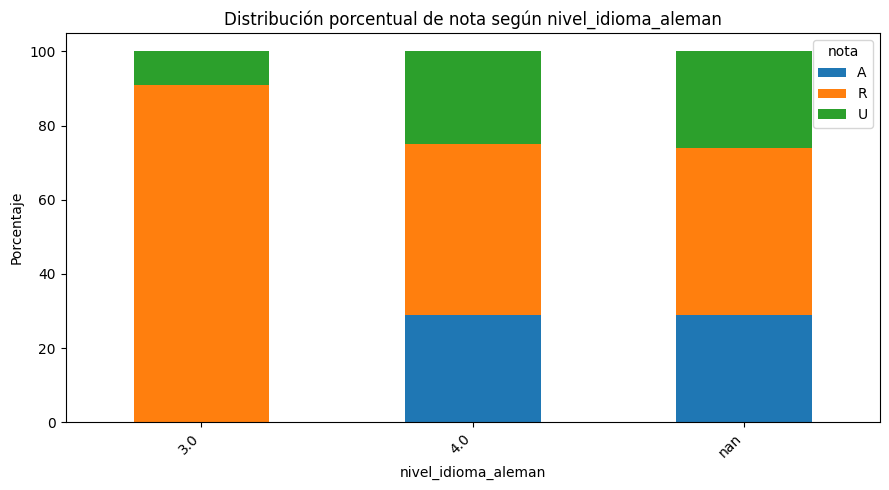


GRUPO: Socioeconómicas

Variable: costeo_estudios_familiar
Frecuencias absolutas:


nota,A,R,U
costeo_estudios_familiar,,,
N,162,260,127
S,117,191,121


Porcentajes por categoría:


nota,A,R,U
costeo_estudios_familiar,,,
N,29.51,47.36,23.13
S,27.27,44.52,28.21


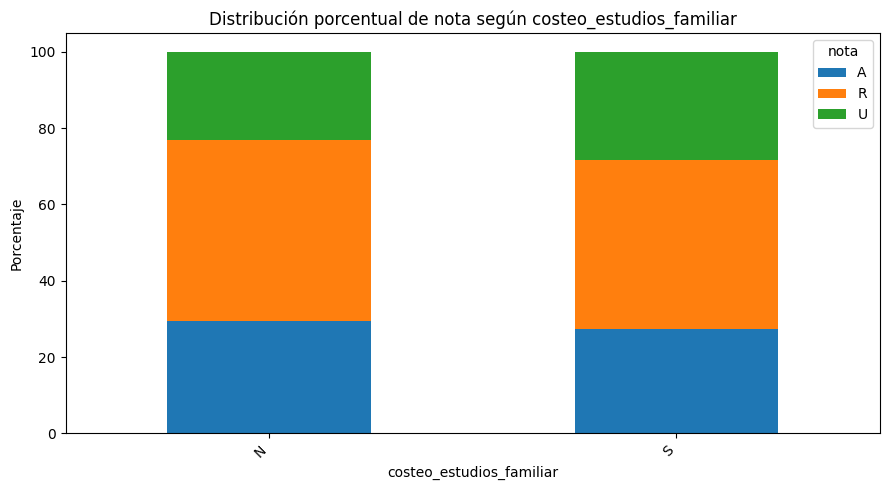


Variable: costeo_estudios_trabajo
Frecuencias absolutas:


nota,A,R,U
costeo_estudios_trabajo,,,
N,262,413,217
S,17,38,31


Porcentajes por categoría:


nota,A,R,U
costeo_estudios_trabajo,,,
N,29.37,46.30,24.33
S,19.77,44.19,36.05


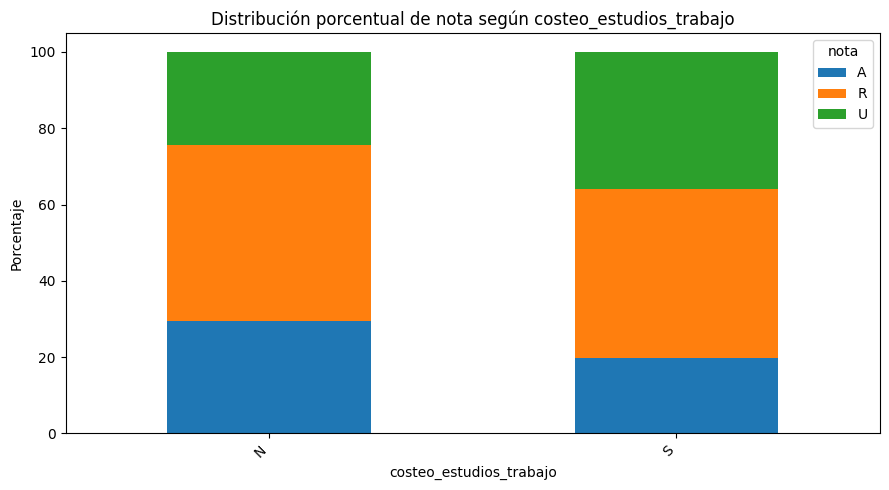


Variable: costeo_estudios_beca
Frecuencias absolutas:


nota,A,R,U
costeo_estudios_beca,,,
N,251,419,228
S,28,32,20


Porcentajes por categoría:


nota,A,R,U
costeo_estudios_beca,,,
N,27.95,46.66,25.39
S,35.00,40.00,25.00


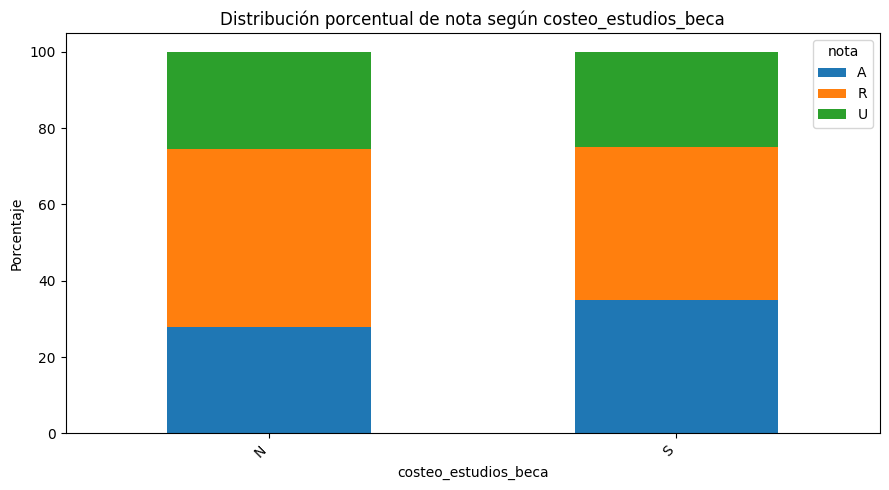


Variable: beca
Frecuencias absolutas:


nota,A,R,U
beca,,,
N,251,419,228
S,28,32,20


Porcentajes por categoría:


nota,A,R,U
beca,,,
N,27.95,46.66,25.39
S,35.00,40.00,25.00


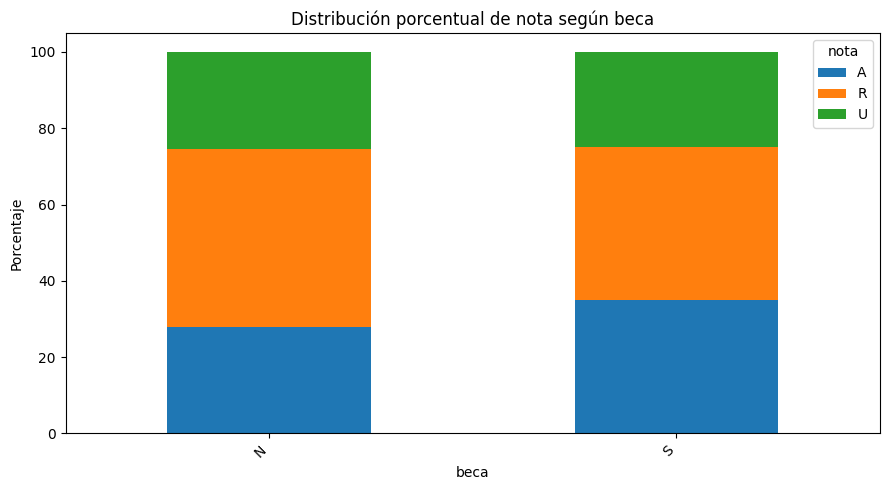


Variable: beca_tipo_economica
Frecuencias absolutas:


nota,A,R,U
beca_tipo_economica,,,
N,253,420,229
S,26,31,19


Porcentajes por categoría:


nota,A,R,U
beca_tipo_economica,,,
N,28.05,46.56,25.39
S,34.21,40.79,25.00


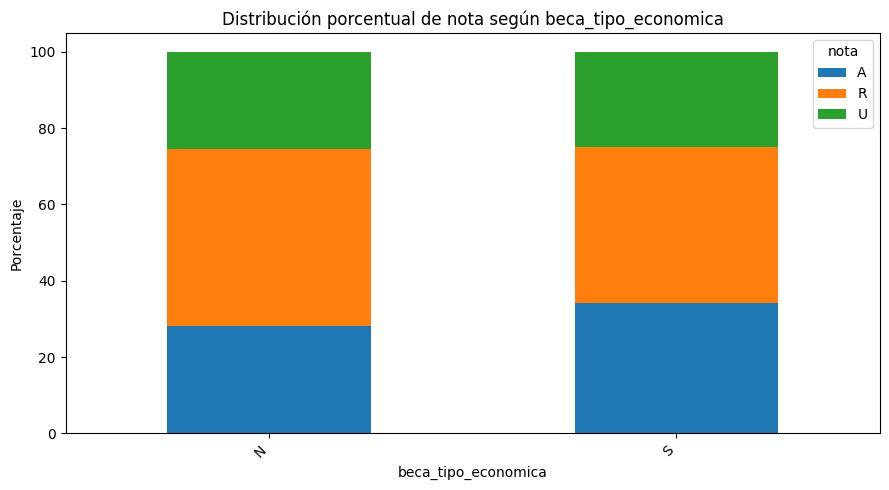


Variable: beca_economica_transporte
Frecuencias absolutas:


nota,A,R,U
beca_economica_transporte,,,
N,276,445,243
S,3,6,5


Porcentajes por categoría:


nota,A,R,U
beca_economica_transporte,,,
N,28.63,46.16,25.21
S,21.43,42.86,35.71


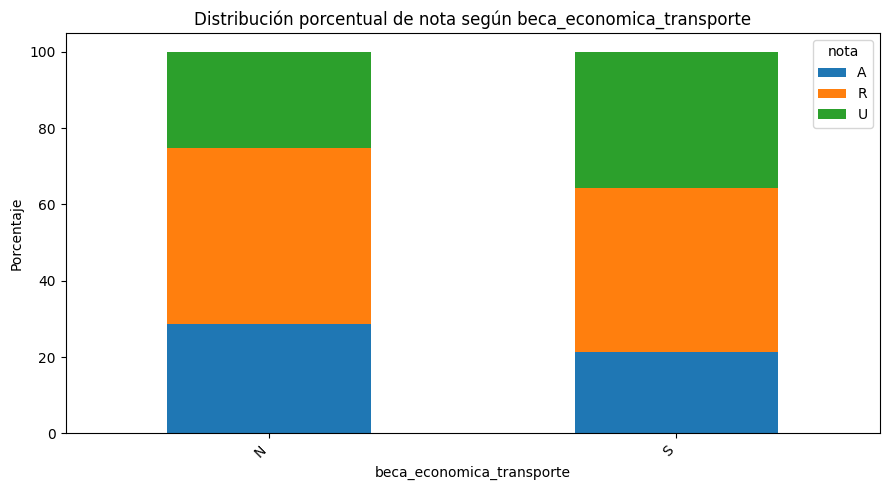


Variable: beca_economica_comedor
Frecuencias absolutas:


nota,A,R,U
beca_economica_comedor,,,
N,274,440,244
S,5,11,4


Porcentajes por categoría:


nota,A,R,U
beca_economica_comedor,,,
N,28.6,45.93,25.47
S,25.0,55.00,20.00


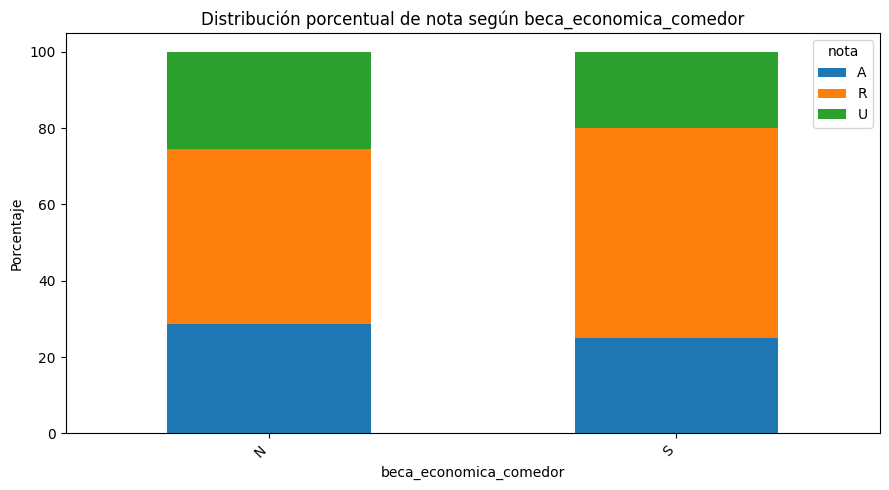


GRUPO: Laborales

Variable: trabajo_existe
Frecuencias absolutas:


nota,A,R,U
trabajo_existe,,,
1,28,48,38
2,71,143,73
3,179,257,132
4,1,3,5


Porcentajes por categoría:


nota,A,R,U
trabajo_existe,,,
1,24.56,42.11,33.33
2,24.74,49.83,25.44
3,31.51,45.25,23.24
4,11.11,33.33,55.56


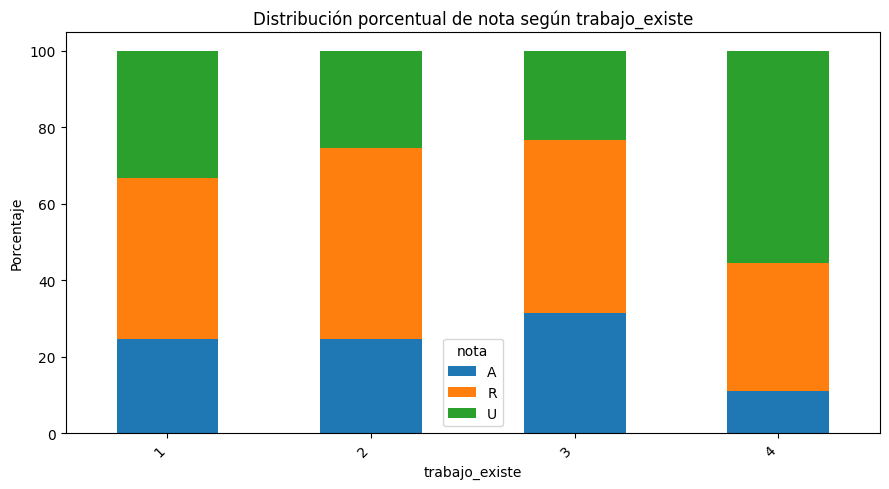


Variable: trabajo_hace
Frecuencias absolutas:


nota,A,R,U
trabajo_hace,,,
1.0,3,3,0
2.0,9,15,15
3.0,9,20,19
4.0,0,0,1
NaN,258,413,213


Porcentajes por categoría:


nota,A,R,U
trabajo_hace,,,
1.0,50.00,50.00,0.00
2.0,23.08,38.46,38.46
3.0,18.75,41.67,39.58
4.0,0.00,0.00,100.00
NaN,29.19,46.72,24.10


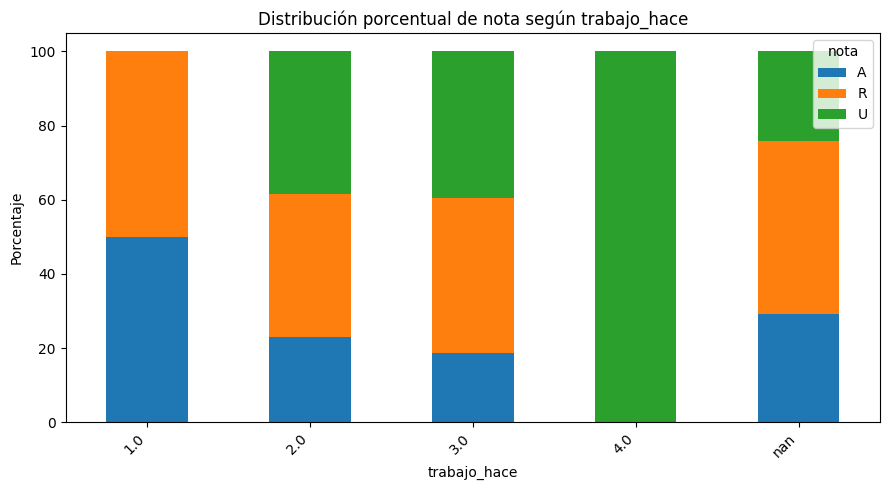


Variable: trabajo_ocupacion
Frecuencias absolutas:


nota,A,R,U
trabajo_ocupacion,,,
1.0,5,5,0
2.0,15,29,34
3.0,1,4,1
NaN,258,413,213


Porcentajes por categoría:


nota,A,R,U
trabajo_ocupacion,,,
1.0,50.00,50.00,0.00
2.0,19.23,37.18,43.59
3.0,16.67,66.67,16.67
NaN,29.19,46.72,24.10


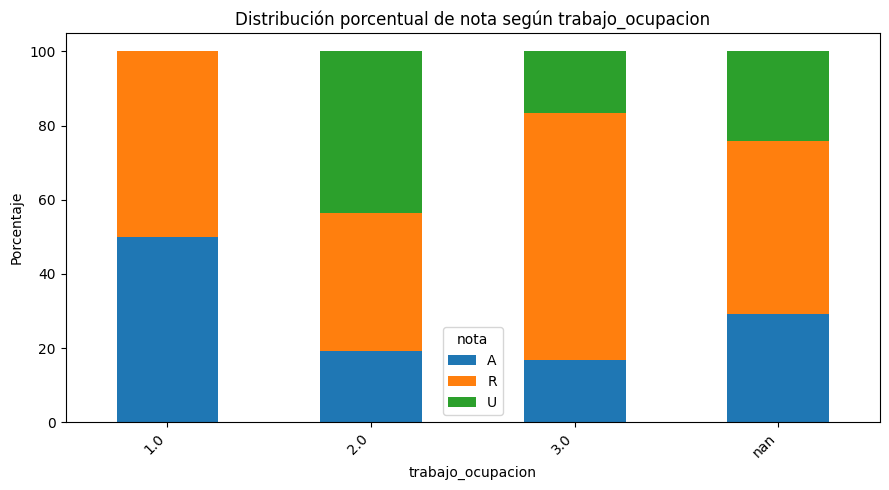


Variable: trabajo_hora_sem
Frecuencias absolutas:


nota,A,R,U
trabajo_hora_sem,,,
1.0,5,13,12
2.0,3,6,7
3.0,6,8,4
4.0,5,6,11
NaN,260,418,214


Porcentajes por categoría:


nota,A,R,U
trabajo_hora_sem,,,
1.0,16.67,43.33,40.00
2.0,18.75,37.50,43.75
3.0,33.33,44.44,22.22
4.0,22.73,27.27,50.00
NaN,29.15,46.86,23.99


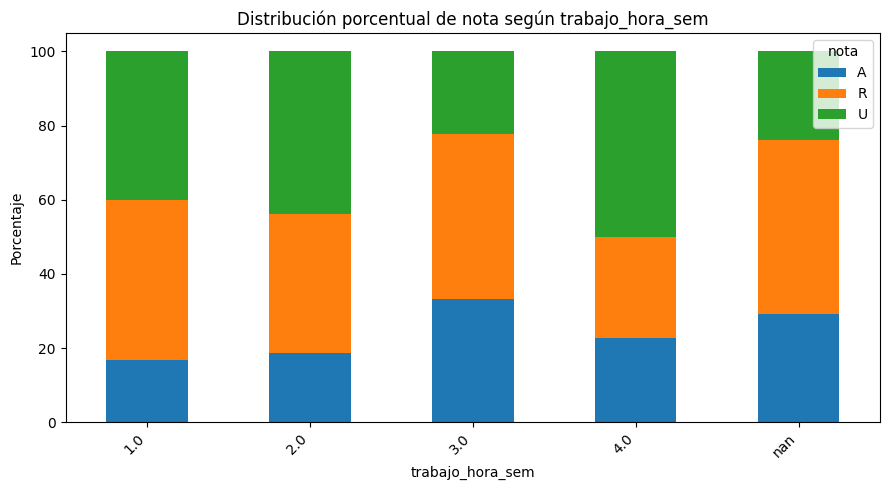


Variable: trabajo_carrera
Frecuencias absolutas:


nota,A,R,U
trabajo_carrera,,,
1.0,1,0,0
2.0,5,10,9
3.0,15,25,21
NaN,258,416,218


Porcentajes por categoría:


nota,A,R,U
trabajo_carrera,,,
1.0,100.00,0.00,0.00
2.0,20.83,41.67,37.50
3.0,24.59,40.98,34.43
NaN,28.92,46.64,24.44


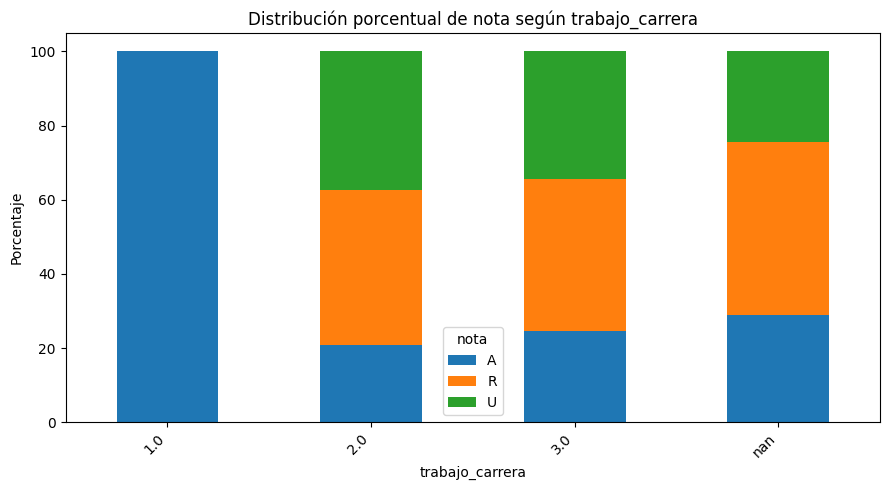


Variable: trabajo_recibe_pago
Frecuencias absolutas:


nota,A,R,U
trabajo_recibe_pago,,,
N,272,436,230
S,7,15,18


Porcentajes por categoría:


nota,A,R,U
trabajo_recibe_pago,,,
N,29.0,46.48,24.52
S,17.5,37.50,45.00


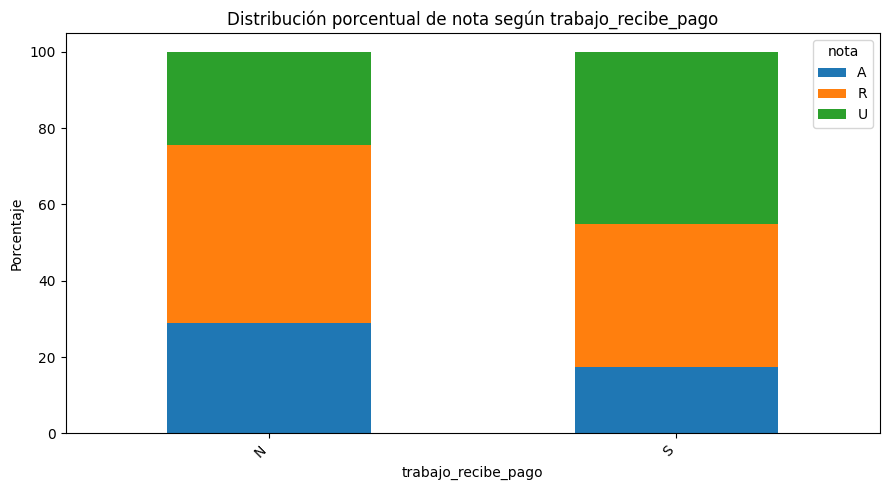


GRUPO: Familiares y personales

Variable: estado_civil
Frecuencias absolutas:


nota,A,R,U
estado_civil,,,
1,276,449,245
2,1,0,2
3,0,1,1
5,2,1,0


Porcentajes por categoría:


nota,A,R,U
estado_civil,,,
1,28.45,46.29,25.26
2,33.33,0.00,66.67
3,0.00,50.00,50.00
5,66.67,33.33,0.00


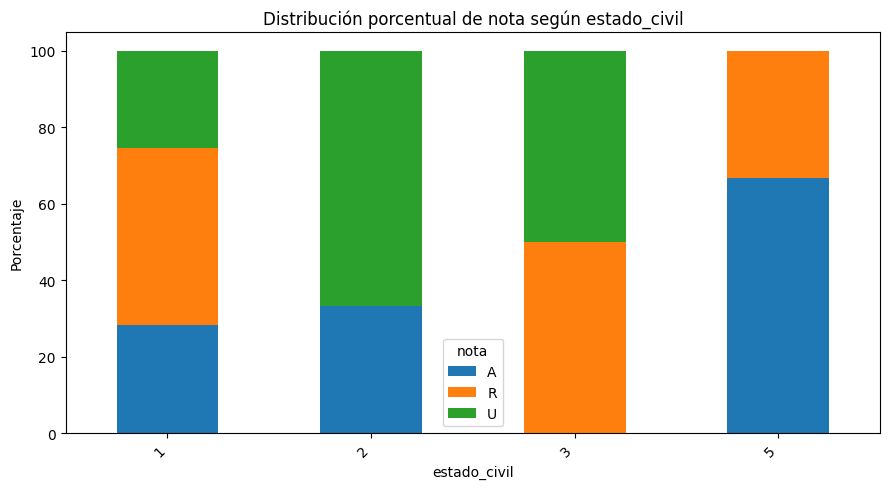


Variable: situacion_padre
Frecuencias absolutas:


nota,A,R,U
situacion_padre,,,
D,9,33,19
N,13,20,14
V,257,398,215


Porcentajes por categoría:


nota,A,R,U
situacion_padre,,,
D,14.75,54.10,31.15
N,27.66,42.55,29.79
V,29.54,45.75,24.71


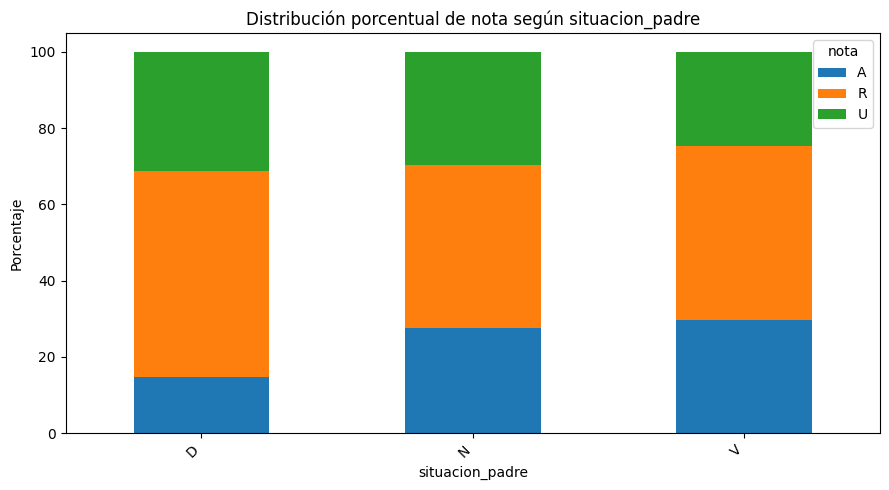


Variable: situacion_madre
Frecuencias absolutas:


nota,A,R,U
situacion_madre,,,
D,0,2,2
N,4,6,9
V,275,443,237


Porcentajes por categoría:


nota,A,R,U
situacion_madre,,,
D,0.00,50.00,50.00
N,21.05,31.58,47.37
V,28.80,46.39,24.82


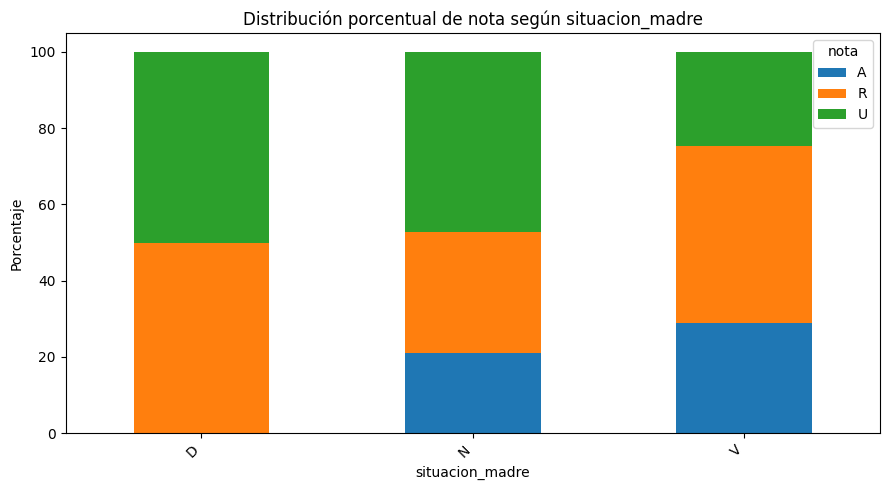


Variable: cantidad_hijos
Frecuencias absolutas:


nota,A,R,U
cantidad_hijos,,,
0,278,451,245
1,1,0,3


Porcentajes por categoría:


nota,A,R,U
cantidad_hijos,,,
0,28.54,46.3,25.15
1,25.00,0.0,75.00


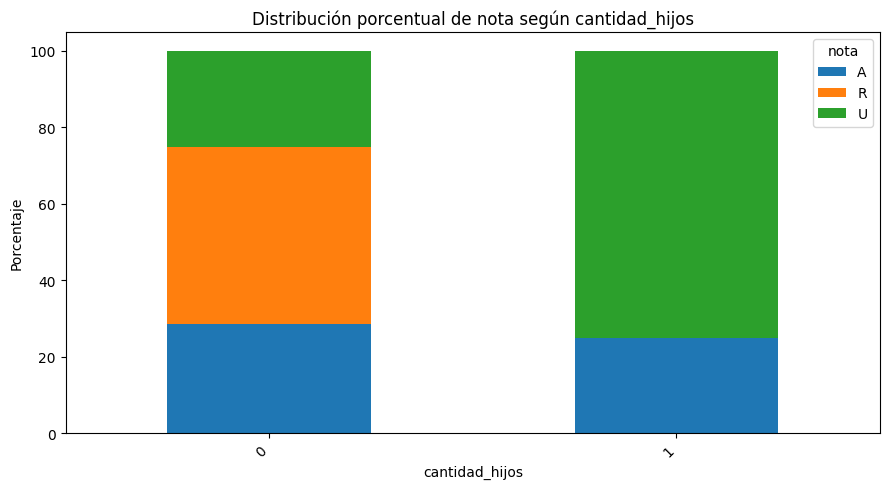


Variable: cantidad_familia
Frecuencias absolutas:


nota,A,R,U
cantidad_familia,,,
0,244,371,181
1,7,21,23
2,25,49,36
3,3,10,8


Porcentajes por categoría:


nota,A,R,U
cantidad_familia,,,
0,30.65,46.61,22.74
1,13.73,41.18,45.10
2,22.73,44.55,32.73
3,14.29,47.62,38.10


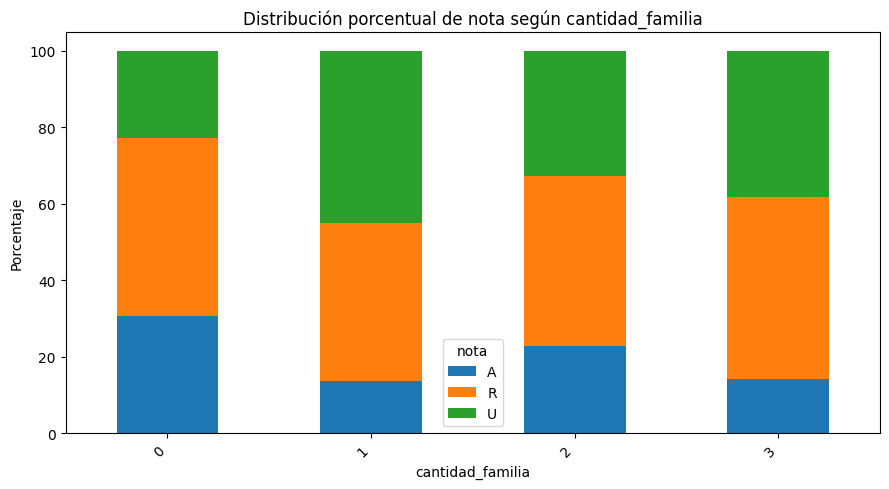


Variable: vive_con
Frecuencias absolutas:


nota,A,R,U
vive_con,,,
1.0,76,94,72
2.0,13,23,9
3.0,169,280,150
4.0,0,2,3
5.0,7,18,8
NaN,14,34,6


Porcentajes por categoría:


nota,A,R,U
vive_con,,,
1.0,31.40,38.84,29.75
2.0,28.89,51.11,20.00
3.0,28.21,46.74,25.04
4.0,0.00,40.00,60.00
5.0,21.21,54.55,24.24
NaN,25.93,62.96,11.11


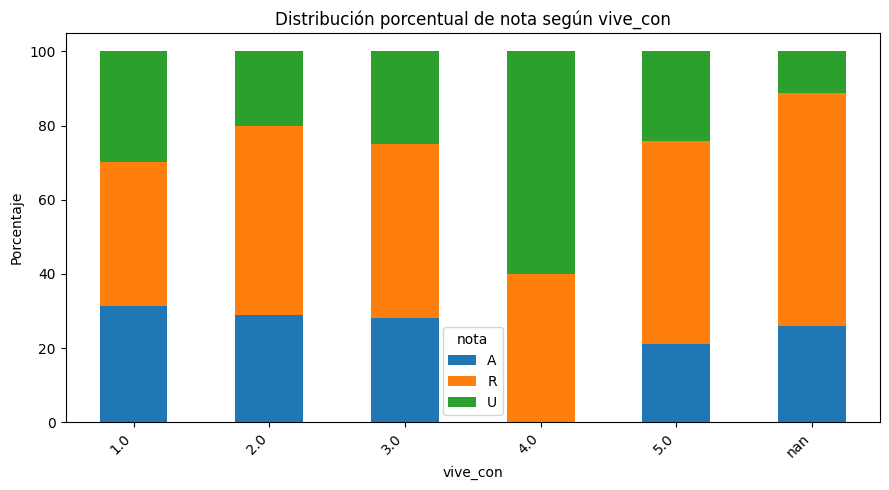


Variable: cobertura_salud
Frecuencias absolutas:


nota,A,R,U
cobertura_salud,,,
1,148,227,123
2,1,5,4
3,42,44,26
4,2,2,4
5,86,173,91


Porcentajes por categoría:


nota,A,R,U
cobertura_salud,,,
1,29.72,45.58,24.70
2,10.00,50.00,40.00
3,37.50,39.29,23.21
4,25.00,25.00,50.00
5,24.57,49.43,26.00


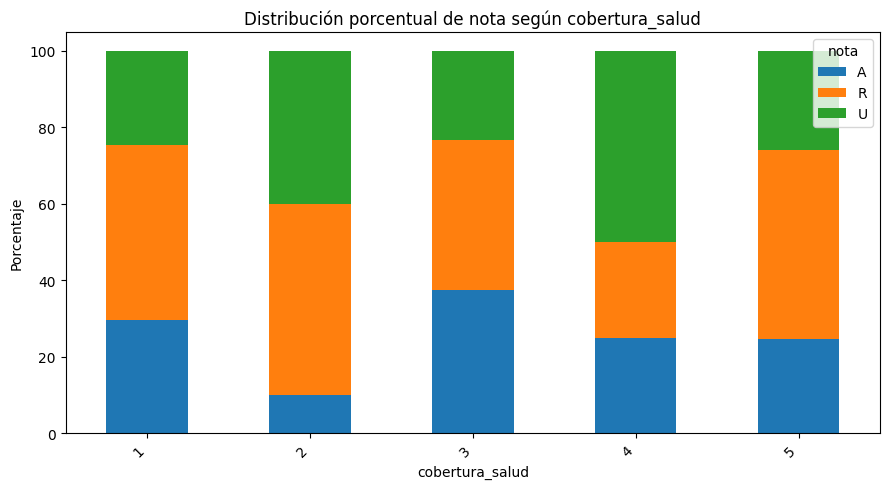


Variable: tipo_vivienda
Frecuencias absolutas:


nota,A,R,U
tipo_vivienda,,,
4.0,12,31,17
5.0,150,249,127
6.0,112,156,97
7.0,4,6,2
8.0,0,2,4
NaN,1,7,1


Porcentajes por categoría:


nota,A,R,U
tipo_vivienda,,,
4.0,20.00,51.67,28.33
5.0,28.52,47.34,24.14
6.0,30.68,42.74,26.58
7.0,33.33,50.00,16.67
8.0,0.00,33.33,66.67
NaN,11.11,77.78,11.11


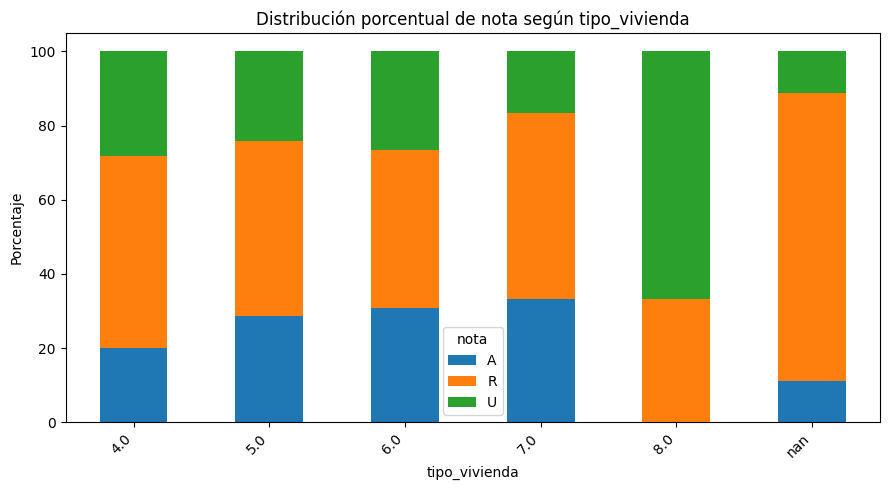


GRUPO: Territoriales

Variable: procedencia_localidad
Frecuencias absolutas:


nota,A,R,U
procedencia_localidad,,,
2744,4,5,3
3905,2,1,0
4419,1,2,2
4479,1,1,2
5294,1,0,3
5342,1,3,3
5367,2,4,0
5432,0,3,0
5436,20,42,18


Porcentajes por categoría:


nota,A,R,U
procedencia_localidad,,,
2744,33.33,41.67,25.00
3905,66.67,33.33,0.00
4419,20.00,40.00,40.00
4479,25.00,25.00,50.00
5294,25.00,0.00,75.00
5342,14.29,42.86,42.86
5367,33.33,66.67,0.00
5432,0.00,100.00,0.00
5436,25.00,52.50,22.50


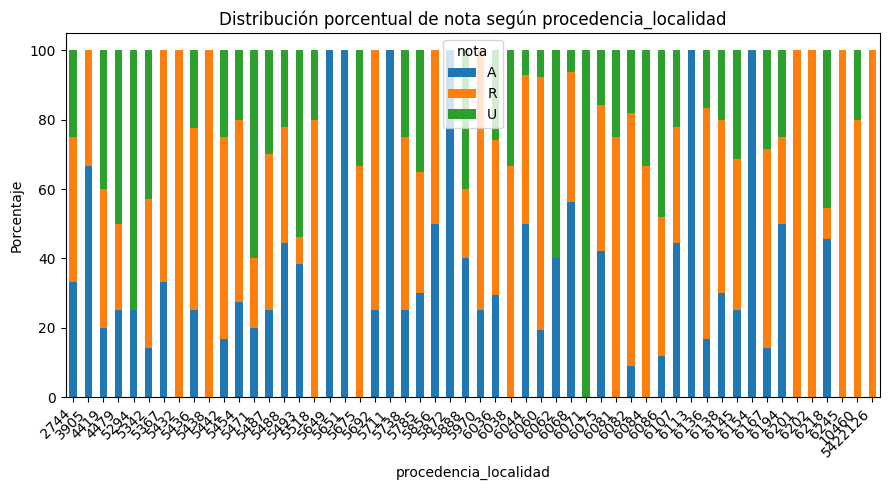


Variable: procedencia_codigo_postal
Frecuencias absolutas:


nota,A,R,U
procedencia_codigo_postal,,,
3061.0,4,5,3
3300.0,2,1,0
3370.0,1,2,2
3400.0,1,1,2
3509.0,1,0,3
3514.0,1,3,3
3515.0,2,4,0
3530.0,20,45,18
3531.0,2,9,3


Porcentajes por categoría:


nota,A,R,U
procedencia_codigo_postal,,,
3061.0,33.33,41.67,25.00
3300.0,66.67,33.33,0.00
3370.0,20.00,40.00,40.00
3400.0,25.00,25.00,50.00
3509.0,25.00,0.00,75.00
3514.0,14.29,42.86,42.86
3515.0,33.33,66.67,0.00
3530.0,24.10,54.22,21.69
3531.0,14.29,64.29,21.43


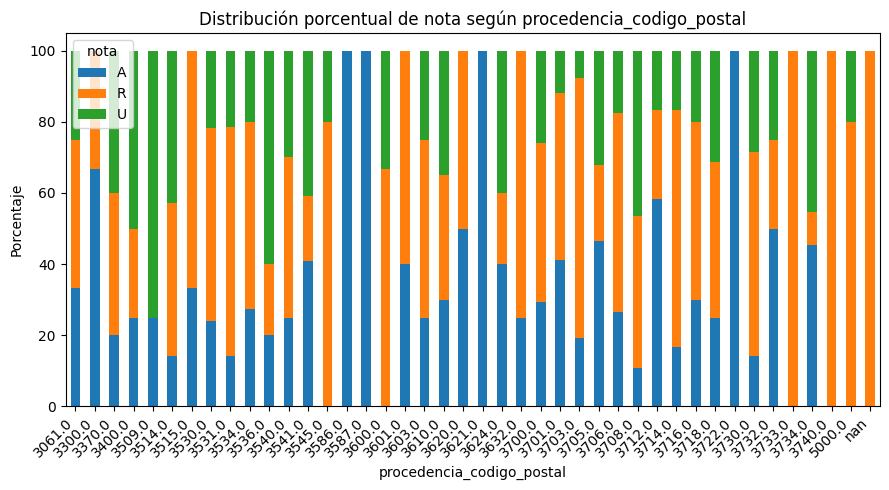


GRUPO: Motivacionales

Variable: mot_vocacion
Frecuencias absolutas:


nota,A,R,U
mot_vocacion,,,
N,249,386,206
S,30,65,42


Porcentajes por categoría:


nota,A,R,U
mot_vocacion,,,
N,29.61,45.90,24.49
S,21.90,47.45,30.66


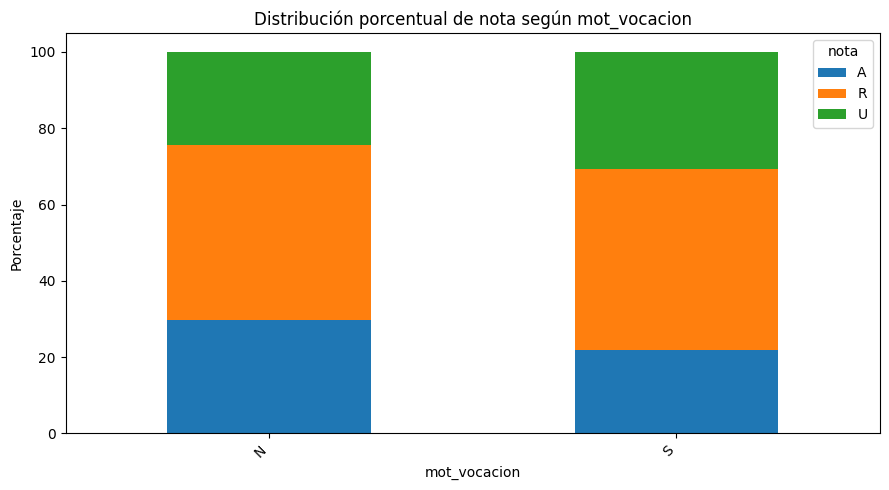


Variable: mot_sugerencia_familiar
Frecuencias absolutas:


nota,A,R,U
mot_sugerencia_familiar,,,
N,266,431,230
S,13,20,18


Porcentajes por categoría:


nota,A,R,U
mot_sugerencia_familiar,,,
N,28.69,46.49,24.81
S,25.49,39.22,35.29


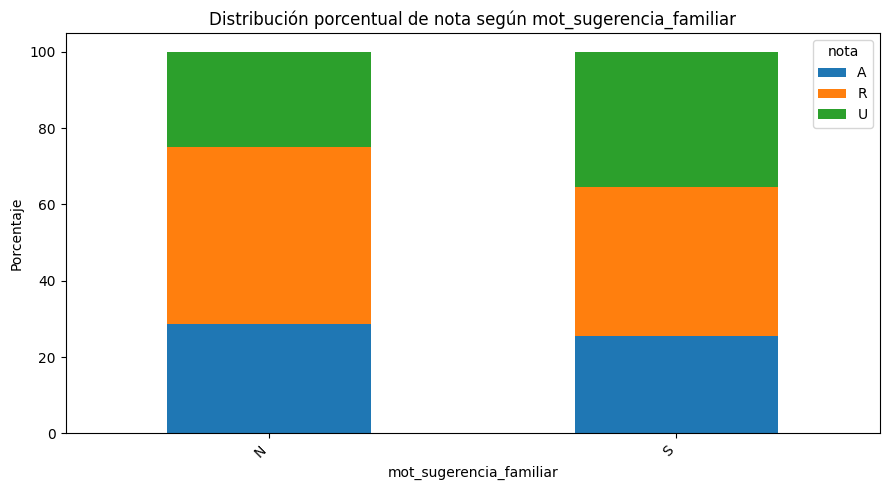


Variable: mot_reconocimiento_social
Frecuencias absolutas:


nota,A,R,U
mot_reconocimiento_social,,,
N,268,435,233
S,11,16,15


Porcentajes por categoría:


nota,A,R,U
mot_reconocimiento_social,,,
N,28.63,46.47,24.89
S,26.19,38.10,35.71


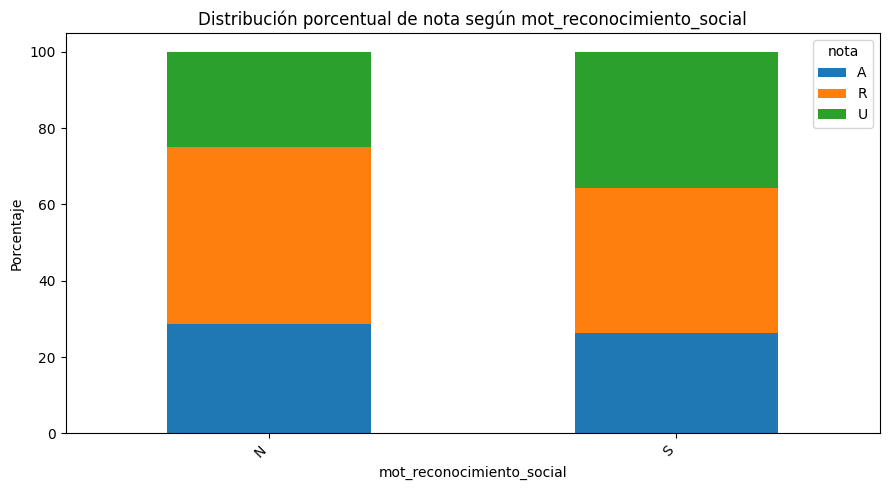


Variable: mot_insercion_laboral
Frecuencias absolutas:


nota,A,R,U
mot_insercion_laboral,,,
N,253,405,211
S,26,46,37


Porcentajes por categoría:


nota,A,R,U
mot_insercion_laboral,,,
N,29.11,46.61,24.28
S,23.85,42.20,33.94


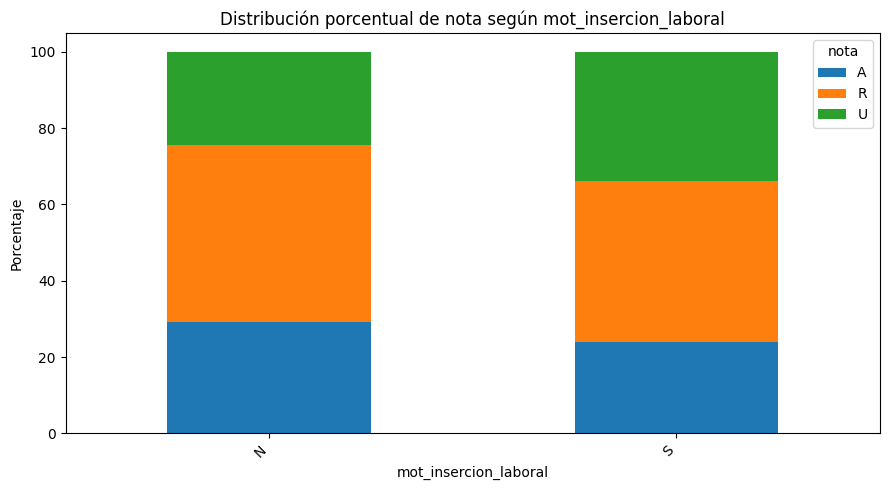


Variable: mot_perfil_profesional
Frecuencias absolutas:


nota,A,R,U
mot_perfil_profesional,,,
N,244,402,210
S,35,49,38


Porcentajes por categoría:


nota,A,R,U
mot_perfil_profesional,,,
N,28.50,46.96,24.53
S,28.69,40.16,31.15


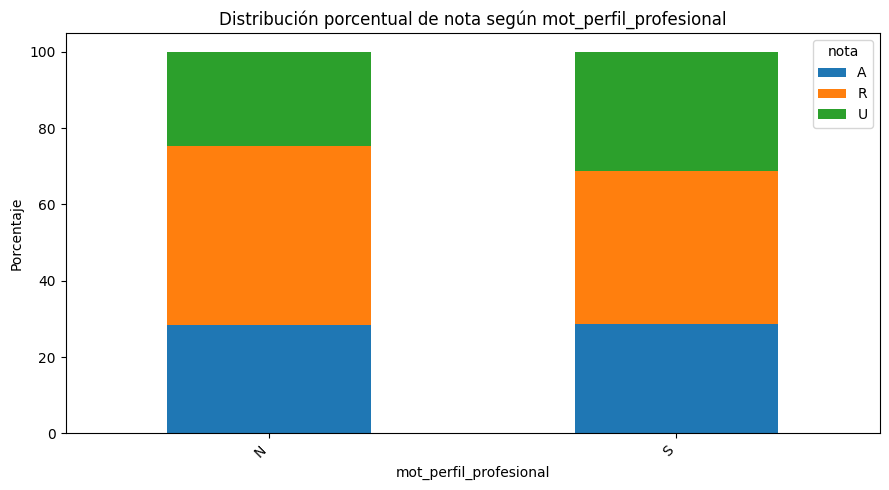


Variable: mot_mejora_economica
Frecuencias absolutas:


nota,A,R,U
mot_mejora_economica,,,
N,244,400,203
S,35,51,45


Porcentajes por categoría:


nota,A,R,U
mot_mejora_economica,,,
N,28.81,47.23,23.97
S,26.72,38.93,34.35


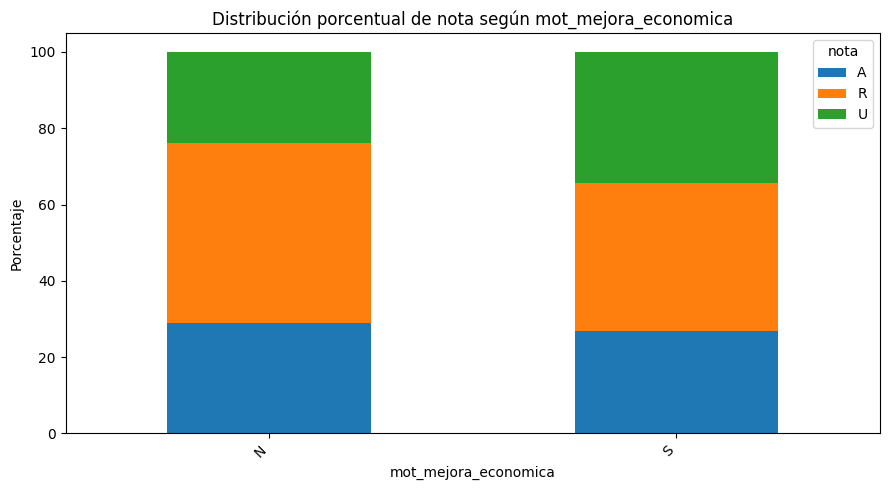


Variable: mot_util_sociedad
Frecuencias absolutas:


nota,A,R,U
mot_util_sociedad,,,
N,259,403,205
S,20,48,43


Porcentajes por categoría:


nota,A,R,U
mot_util_sociedad,,,
N,29.87,46.48,23.64
S,18.02,43.24,38.74


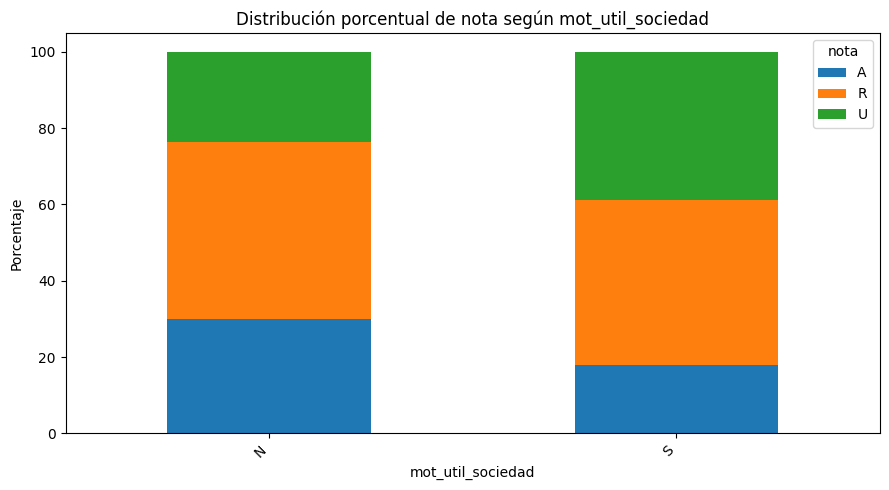


Variable: mot_otros_p
Frecuencias absolutas:


nota,A,R,U
mot_otros_p,,,
N,269,429,236
S,10,22,12


Porcentajes por categoría:


nota,A,R,U
mot_otros_p,,,
N,28.80,45.93,25.27
S,22.73,50.00,27.27


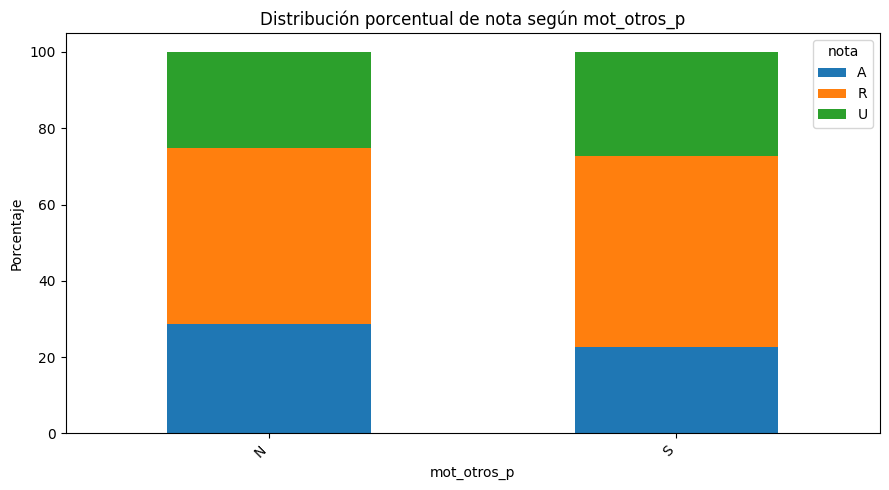

In [ ]:
resultados_tablas_abs = {}
resultados_tablas_pct = {}

carpeta_graficos = Path("graficos_variables_predictoras")
carpeta_graficos.mkdir(parents=True, exist_ok=True)

for grupo, variables in grupos_variables.items():
    variables_existentes = [
        v for v in variables
        if v in df_eda.columns
        and v in variables_eda
    ]

    print("\n" + "=" * 90)
    print(f"GRUPO: {grupo}")
    print("=" * 90)

    for variable in variables_existentes:
        tabla_abs, tabla_pct = tabla_variable_vs_objetivo(
            df_eda,
            variable
        )

        resultados_tablas_abs[variable] = tabla_abs
        resultados_tablas_pct[variable] = tabla_pct

        print(f"\nVariable: {variable}")
        print("Frecuencias absolutas:")
        display(tabla_abs)

        print("Porcentajes por categoría:")
        display(tabla_pct)

        graficar_variable_vs_objetivo(
            df_eda,
            variable,
            carpeta_salida=carpeta_graficos
        )

## 10. Ranking exploratorio de variables

In [ ]:
ranking_variables = []

for grupo, variables in grupos_variables.items():
    for variable in variables:
        if variable not in df_eda.columns:
            continue

        if variable not in variables_eda:
            continue

        # Se omiten variables de alta cardinalidad en este ranking simple.
        if df_eda[variable].nunique(dropna=True) > 30:
            continue

        tabla_pct = (
            pd.crosstab(
                df_eda[variable],
                df_eda[variable_objetivo],
                normalize="index",
                dropna=False
            ) * 100
        )

        if tabla_pct.shape[0] < 2:
            continue

        diferencias_por_clase = (
            tabla_pct.max(axis=0)
            - tabla_pct.min(axis=0)
        )

        ranking_variables.append({
            "grupo": grupo,
            "variable": variable,
            "categorias": df_eda[variable].nunique(dropna=True),
            "diferencia_maxima_puntos_porcentuales": round(
                diferencias_por_clase.max(), 2
            )
        })

ranking_variables = pd.DataFrame(ranking_variables)

if not ranking_variables.empty:
    ranking_variables = (
        ranking_variables
        .sort_values(
            "diferencia_maxima_puntos_porcentuales",
            ascending=False
        )
        .reset_index(drop=True)
    )

display(ranking_variables.head(30))

,grupo,variable,categorias,diferencia_maxima_puntos_porcentuales
0,Laborales,trabajo_hace,4,100.00
1,Idiomas,nivel_idioma_portugues,4,81.16
2,Laborales,trabajo_carrera,3,79.17
3,Familiares y personales,estado_civil,4,66.67
4,Idiomas,nivel_idioma_frances,3,60.47
5,Familiares y personales,tipo_vivienda,5,55.56
6,Familiares y personales,cantidad_hijos,2,49.85
7,Familiares y personales,vive_con,5,48.89
8,Idiomas,nivel_idioma_aleman,2,45.92
9,Laborales,trabajo_ocupacion,3,43.59


## 11. Exportación del reporte

In [ ]:
nombre_reporte = "Reporte_analisis_variables_predictoras.xlsx"

with pd.ExcelWriter(nombre_reporte, engine="openpyxl") as writer:
    resumen_variables.to_excel(
        writer,
        sheet_name="Resumen_variables",
        index=False
    )

    resumen_tipos.to_excel(
        writer,
        sheet_name="Resumen_tipos",
        index=False
    )

    ranking_variables.to_excel(
        writer,
        sheet_name="Ranking_variables",
        index=False
    )

    for variable, tabla in resultados_tablas_pct.items():
        nombre_hoja = variable[:31]
        tabla.to_excel(writer, sheet_name=nombre_hoja)

print(f"Reporte generado: {nombre_reporte}")
files.download(nombre_reporte)

Reporte generado: Reporte_analisis_variables_predictoras.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Descarga de los gráficos

In [ ]:
nombre_base_zip = "graficos_variables_predictoras"
nombre_zip = f"{nombre_base_zip}.zip"

if carpeta_graficos.exists():
    shutil.make_archive(
        nombre_base_zip,
        "zip",
        carpeta_graficos
    )
    print(f"Archivo generado: {nombre_zip}")
    files.download(nombre_zip)
else:
    print("No se encontró la carpeta de gráficos.")

Archivo generado: graficos_variables_predictoras.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>